In [4]:
import pandas as pd
import numpy as np

train_data = pd.read_csv("week3.csv",skiprows=1,header=None)
X=train_data.iloc[:, :2].values # Two feature values
y=train_data.iloc[: ,2].values # Target values

# (i)(a) 3D-Plot

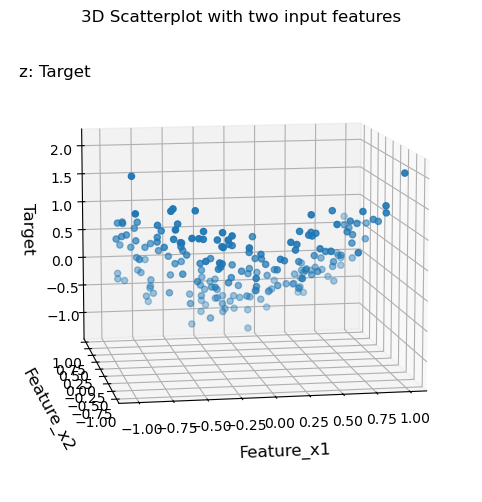

In [2]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X[:,0], X[:,1], y)
ax.set_xlabel("Feature_x1",fontsize=12,labelpad=10)
ax.set_ylabel("Feature_x2",fontsize=12,labelpad=10)
ax.set_zlabel("Target",fontsize=12,labelpad=10)
ax.set_title("3D Scatterplot with two input features")
ax.text2D(0.02, 0.9, "z: Target", transform=ax.transAxes, fontsize=12)
ax.view_init(elev=10, azim=-100)

fig.subplots_adjust(left=0.05, right=0.85)
plt.show()

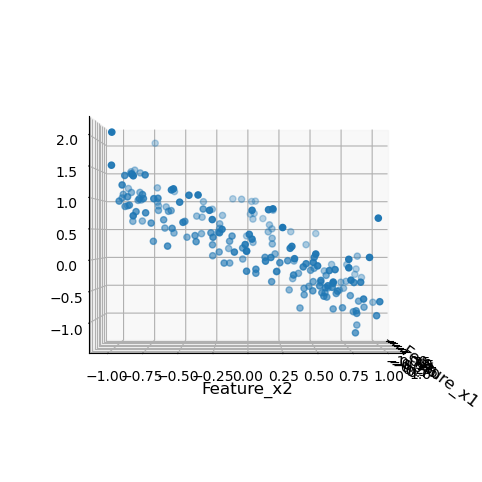

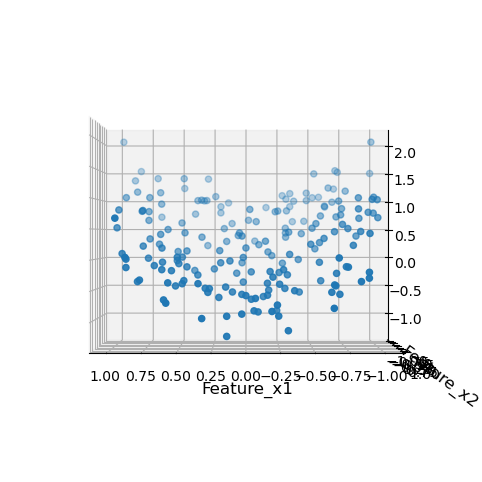

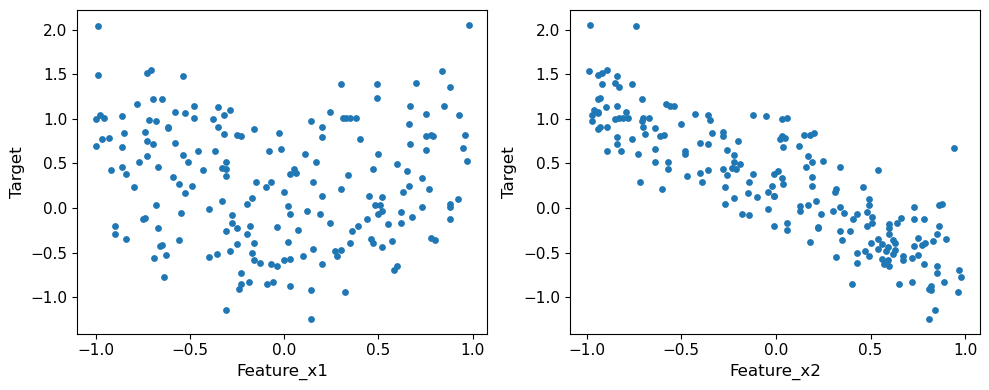

In [6]:
# 1. Side-on 3D views (one figure each, so you can save them for the report)
for elev, azim, name in [(0, 0, "side_view_a"), (0, 90, "side_view_b")]:
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(X[:, 0], X[:, 1], y)
    ax.set_xlabel("Feature_x1", fontsize=12)
    ax.set_ylabel("Feature_x2", fontsize=12)
    ax.view_init(elev=elev, azim=azim)
    plt.show()

# 2. Target vs each feature in 2D
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax2d in enumerate(axes):
    ax2d.scatter(X[:, i], y, s=15)
    ax2d.set_xlabel(f"Feature_x{i+1}", fontsize=12)
    ax2d.set_ylabel("Target", fontsize=12)
    ax2d.tick_params(labelsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# If sklearn is not installed on your machine
# %pip install scikit-learn

<class 'ValueError'>: Can't find a pure Python 3 wheel for 'sklearn'.
See: https://pyodide.org/en/stable/usage/faq.html#why-can-t-micropip-find-a-pure-python-wheel-for-a-package
You can use `await micropip.install(..., keep_going=True)` to get a list of all packages with missing wheels.

In [7]:
# PolynomialFeatures function
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Lasso

# Polynomial features
poly_features = PolynomialFeatures(5,include_bias=False) # add extra polynomial features equal to all combinations of powers of the two features up to power 5
X_poly = poly_features.fit_transform(X)
feature_names = poly_features.get_feature_names_out(["x1","x2"]) 

# Predictions grid
grid = np.linspace(-2,2,40)
g1,g2 = np.meshgrid(grid,grid)
X_grid = np.column_stack((g1.ravel(),g2.ravel()))
X_grid_poly = poly_features.transform(X_grid) # input to the model for prediction

C_range = [0.001,0.01,0.1,1.0,10,100,1000] # smallest C should give all parameters as 0

lasso_coef_table = pd.DataFrame(index=["Intercepts"] + list(feature_names))
lasso_pred = {}

# Lasso regression model
for C in C_range:
    lasso_model = Lasso(alpha = 1/ (2*C), max_iter=1000)  # weight parameter α = 1/(2C) in sklearn
    lasso_model.fit(X_poly,y)
    lasso_pred[C] = lasso_model.predict(X_grid_poly).reshape(g1.shape)
    lasso_coef_table[f"C={C}"] = np.concatenate([[lasso_model.intercept_], lasso_model.coef_])

pd.set_option("display.float_format", "{:.3f}".format)
print(lasso_coef_table)
print("Non-zero coefficients per C:")
print((lasso_coef_table.iloc[1:] != 0).sum())

            C=0.001  C=0.01  C=0.1  C=1.0   C=10  C=100  C=1000
Intercepts    0.283   0.283  0.283  0.283  0.166 -0.005  -0.016
x1            0.000   0.000  0.000  0.000 -0.000 -0.000  -0.000
x2            0.000   0.000  0.000  0.000 -0.834 -0.974  -0.971
x1^2          0.000   0.000  0.000  0.000  0.382  0.938   0.979
x1 x2         0.000   0.000  0.000  0.000  0.000  0.000  -0.000
x2^2          0.000   0.000  0.000  0.000  0.000 -0.000  -0.010
x1^3          0.000   0.000  0.000  0.000 -0.000 -0.000  -0.103
x1^2 x2       0.000   0.000  0.000  0.000 -0.000  0.000  -0.000
x1 x2^2       0.000   0.000  0.000  0.000  0.000  0.018  -0.000
x2^3          0.000   0.000  0.000  0.000 -0.000 -0.000  -0.085
x1^4          0.000   0.000  0.000  0.000  0.000  0.000   0.000
x1^3 x2       0.000   0.000  0.000  0.000  0.000  0.000   0.082
x1^2 x2^2     0.000   0.000  0.000  0.000  0.000  0.000   0.000
x1 x2^3       0.000   0.000  0.000  0.000  0.000  0.000   0.000
x2^4          0.000   0.000  0.000  0.00

In [8]:
y.mean()

np.float64(0.282818272271072)

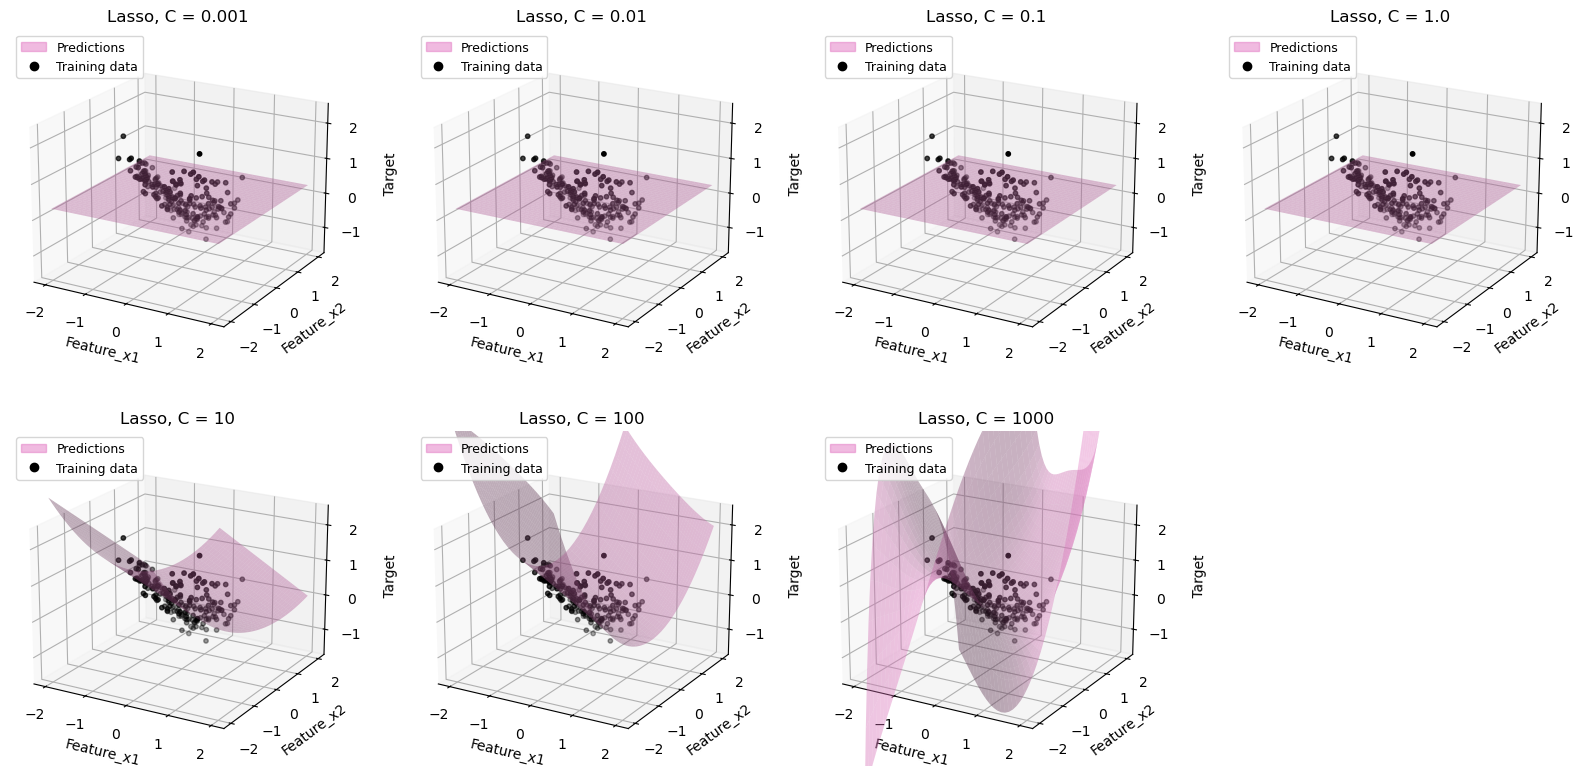

In [9]:
# Lasso model plot
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# C_range_plot = [1,10,100,1000]

lasso_plot = plt.figure(figsize=(20,20))
for i, C in enumerate(C_range, start=1):
    ax = lasso_plot.add_subplot(4, 4, i, projection="3d")
    ax.plot_surface(g1, g2, lasso_pred[C], alpha=0.4, color="tab:pink")
    ax.scatter(X[:, 0], X[:, 1], y, color="k", s=10)
    ax.set_zlim(y.min() - 0.5, y.max() + 0.5) # To depict overfitting for larger C values
    #ax.set_zlim(-5,5)
    ax.set_xlabel("Feature_x1", fontsize=10)
    ax.set_ylabel("Feature_x2", fontsize=10)
    ax.set_zlabel("Target", fontsize=10, labelpad=8)
    ax.set_title(f"Lasso, C = {C}", fontsize=12)
    ax.view_init(elev=20, azim=-60)
    ax.legend(handles=[Patch(color="tab:pink", alpha=0.5, label="Predictions"),
                       Line2D([0], [0], marker="o", color="k", linestyle="", label="Training data")],
              loc="upper left", fontsize=9)

plt.show()

In [10]:
# Ridge regression model 
from sklearn.linear_model import Ridge

m = X_poly.shape[0] # No. of training data points

ridge_coef_table = pd.DataFrame(index=["Intercepts"] + list(feature_names))
ridge_pred = {}

# Ridge regression model
for C in C_range:
    ridge_model = Ridge(alpha = m/C, max_iter=1000)  # weight parameter α = m/C for Ridge in sklearn
    ridge_model.fit(X_poly,y)
    ridge_pred[C] = ridge_model.predict(X_grid_poly).reshape(g1.shape)
    ridge_coef_table[f"C={C}"] = np.concatenate([[ridge_model.intercept_], ridge_model.coef_])

pd.set_option("display.float_format", "{:.3f}".format)
print(ridge_coef_table)

            C=0.001  C=0.01  C=0.1  C=1.0   C=10  C=100  C=1000
Intercepts    0.283   0.282  0.277  0.235  0.118  0.041   0.004
x1           -0.000  -0.000 -0.003 -0.015 -0.018 -0.007   0.083
x2           -0.000  -0.003 -0.032 -0.214 -0.570 -0.855  -0.887
x1^2          0.000   0.001  0.007  0.068  0.329  0.605   0.854
x1 x2         0.000   0.000  0.002  0.010  0.015 -0.017  -0.083
x2^2          0.000   0.000  0.002  0.010 -0.019 -0.048  -0.039
x1^3         -0.000  -0.000 -0.002 -0.012 -0.032 -0.086  -0.402
x1^2 x2      -0.000  -0.001 -0.009 -0.056 -0.082 -0.047  -0.126
x1 x2^2      -0.000  -0.000 -0.000  0.003  0.039  0.047  -0.139
x2^3         -0.000  -0.002 -0.019 -0.125 -0.255 -0.225  -0.317
x1^4          0.000   0.001  0.006  0.056  0.257  0.316   0.126
x1^3 x2       0.000   0.000  0.001  0.005  0.020  0.056   0.132
x1^2 x2^2     0.000   0.000  0.003  0.024  0.092  0.124   0.072
x1 x2^3       0.000   0.000  0.001  0.007  0.017  0.042   0.089
x2^4          0.000   0.000  0.003  0.01

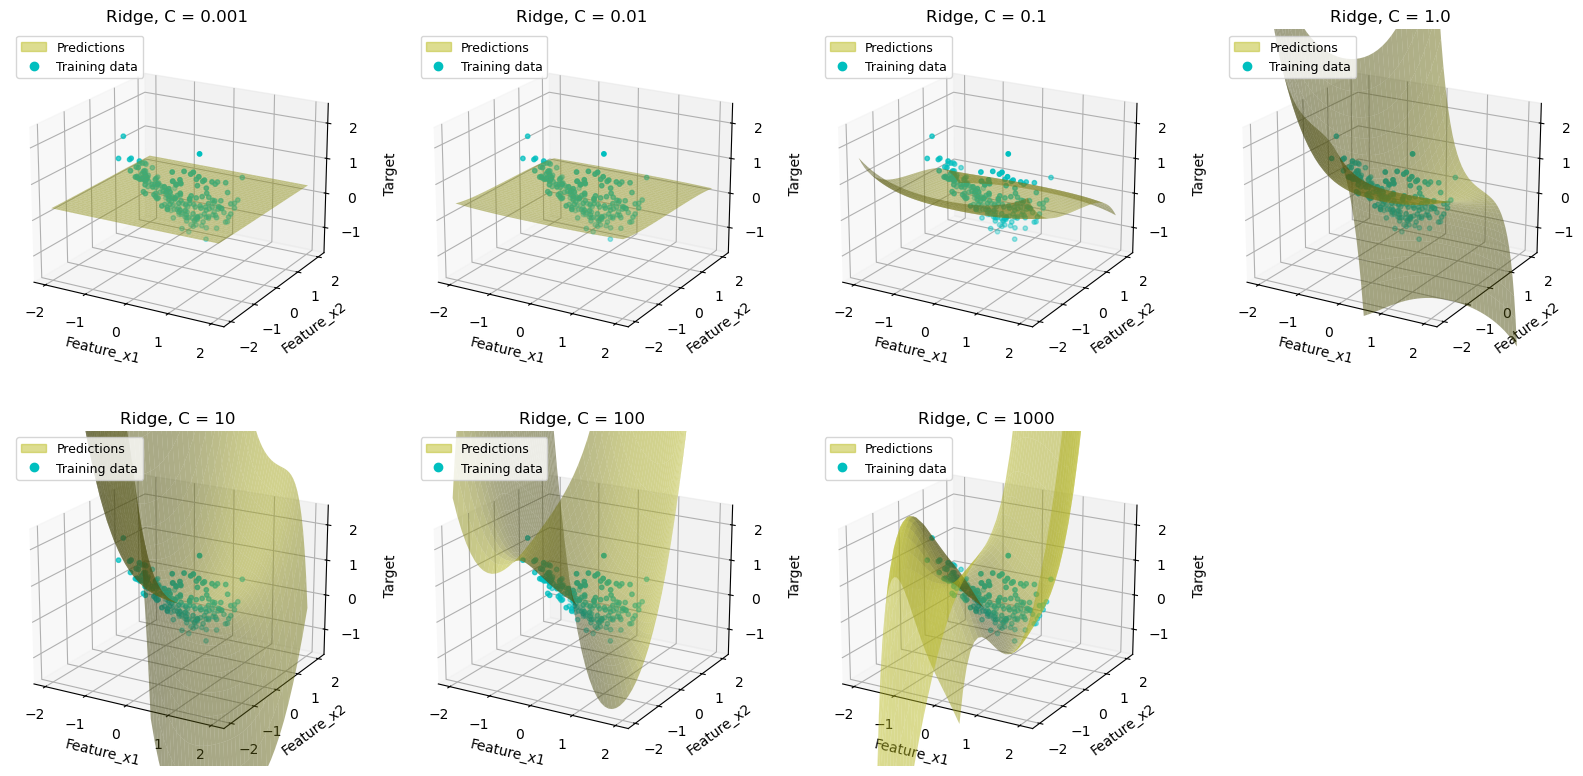

In [11]:
# Ridge plot
ridge_plot = plt.figure(figsize=(20,20))
for i, C in enumerate(C_range, start=1):
    ax = ridge_plot.add_subplot(4, 4, i, projection="3d")
    ax.plot_surface(g1, g2, ridge_pred[C], alpha=0.5, color="tab:olive")
    ax.scatter(X[:, 0], X[:, 1], y, color="c", s=10)
    ax.set_zlim(y.min() - 0.5, y.max() + 0.5) # To depict overfitting for larger C values
    #ax.set_zlim(-5,5)
    ax.set_xlabel("Feature_x1", fontsize=10)
    ax.set_ylabel("Feature_x2", fontsize=10)
    ax.set_zlabel("Target", fontsize=10, labelpad=8)
    ax.set_title(f"Ridge, C = {C}", fontsize=12)
    ax.view_init(elev=20, azim=-60)
    ax.legend(handles=[Patch(color="tab:olive", alpha=0.5, label="Predictions"),
                       Line2D([0], [0], marker="o", color="c", linestyle="", label="Training data")],
              loc="upper left", fontsize=9)

plt.show()

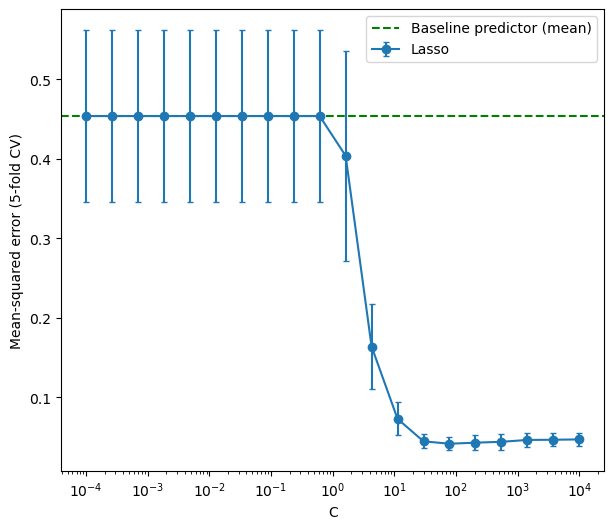

In [31]:
# k-fold cross validation for Lasso model 
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

kf = KFold(n_splits=5)
C_range_lasso = np.logspace(-4,4,20)

def fold_errors(lasso_model_cross_val):
    kfold_errors = []
    for train,test in kf.split(X_poly):
        lasso_model_cross_val.fit(X_poly[train],y[train])
        kfold_errors.append(mean_squared_error(y[test], lasso_model_cross_val.predict(X_poly[test])))
    return np.mean(kfold_errors), np.std(kfold_errors)

mean_error, std_error =[],[]

# Calculate mean and std for each C value in C_range
for c in C_range_lasso:
    m,s = fold_errors(Lasso(alpha = 1/ (2*c), max_iter=100000))
    mean_error.append(m)
    std_error.append(s)

# Preparing a baseline model
baseline_mean, _ = fold_errors(DummyRegressor(strategy='mean'))

plt.figure(figsize=(7,6))
plt.errorbar(C_range_lasso,mean_error, yerr=std_error, fmt = 'o-', capsize = 2, label='Lasso')
plt.axhline(baseline_mean, color ='g', linestyle = '--', label = "Baseline predictor (mean)")
plt.xscale('log')
plt.xlabel('C',fontsize=10)
plt.ylabel('Mean-squared error (5-fold CV)', fontsize=10)
plt.legend(fontsize=10)
plt.show()



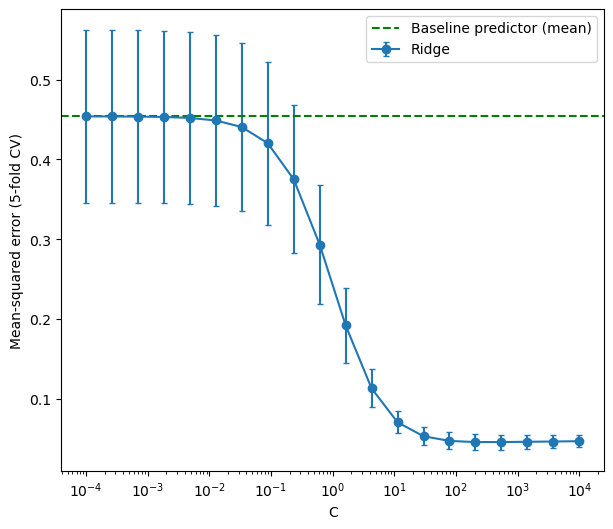

In [32]:
# k-fold cross validation for Ridge model 
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

kf = KFold(n_splits=5)
C_range_ridge = np.logspace(-4,4,20)

def Ridge_CV_MSE(C):
    kfold_errors = []
    for train,test in kf.split(X_poly):
        alpha = len(train)/C
        ridge_model_cross_val = Ridge(alpha=alpha).fit(X_poly[train], y[train])
        kfold_errors.append(mean_squared_error(y[test], ridge_model_cross_val.predict(X_poly[test])))
    return np.mean(kfold_errors), np.std(kfold_errors)

mean_error_ridge, std_error_ridge =[],[]

# Calculate mean and std for each C value in C_range
for C in C_range_ridge:
    m,s = Ridge_CV_MSE(C)
    mean_error_ridge.append(m)
    std_error_ridge.append(s)

# Preparing a baseline model
baseline_mean, _ = fold_errors(DummyRegressor(strategy='mean'))

plt.figure(figsize=(7,6))
plt.errorbar(C_range_ridge,mean_error_ridge, yerr=std_error_ridge, fmt = 'o-', capsize = 2, label='Ridge')
plt.axhline(baseline_mean, color ='g', linestyle = '--', label = "Baseline predictor (mean)")
plt.xscale('log')
plt.xlabel('C',fontsize=10)
plt.ylabel('Mean-squared error (5-fold CV)', fontsize=10)
plt.legend(fontsize=10)
plt.show()